In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os
import pandas as pd
import networkx as nx
import datetime
import time
import random
import plotly.express as px
import seaborn as sns
import scipy.special as scispe
import seaborn as sns
import plotly.figure_factory as ff
import pickle
from IPython.display import clear_output
from plotly.subplots import make_subplots
import plotly.graph_objects as go

from hypnetperturb.utils import *
from hypnetperturb.embedding.coalescent_embedding import *
from hypnetperturb.visualization import *
from hypnetperturb.metrics.kNdist_score import *
from hypnetperturb.perturb_network import *
from hypnetperturb.generate_network import *

In [12]:
model = "WattsStrogatz"
N = 150
kl = 20 #k lattice
pr = 0.1 #p rewiring

## LOOP on GRAPH realisations
n_G = 3
print('n_G =',n_G)

graphs = {}
degrees = {}
clusterings = {}
clusterings_int2 = {}
scores={}

for i in range(n_G):

    graphs[i] = nx.watts_strogatz_graph(N,kl,pr)
   
    degrees[i] = np.array(list(nx.degree(graphs[i])))[:,1]
    clusterings[i] = np.array([val for val in nx.clustering(graphs[i]).values()])
    clusterings_int2[i] = (np.round(clusterings[i],2)*10**2).astype('int')  #clustering values approximate to the second decimal and multiplied for 10**2 to give a int value, to classify nodes based on their clustering
    scores[i] = {i:np.array([]) for i in range(N)} 

degrees_unique_union = np.unique([degrees[i] for i in range(n_G)]) # union of degree classes across all graphs
clusterings_int2_unique_union = np.unique([clusterings_int2[i] for i in range(n_G)])

n_G = 3


#### Embedding original graph

In [13]:
 # Embedding parameters 
embedding_parameters_dict = {
'pre_weight':True,  
'binarize':True,
'dim_red_method':'ISOMAP',   
'eq_adj':True, 
'eta_r':8,
'beta_r':0.8,
'weight_r':False,
'res_dict':True
}

output_folder = 'OUTPUT-MEDIA-test-BL/output_nG_iso/'
media_folder = 'OUTPUT-MEDIA-test-BL/media_nG_iso/'

#### Other parameters

In [14]:
# number of NN to take into account
k = 3

# perturbation magnitude 20-40-60-80%
mag_arr = np.array([10/100, 20/100, 30/100, 40/100, 50/100, 60/100, 70/100, 80/100])

n_t = 10*n_G

## Loop over $n_p$ perturbations


$n_G$ = number of realisations of the random graph considered, we loop on them chosing randomly to which graph among the ones generated we will apply the perturbation

$n_p$ = number of random perturbations I apply, a certain fraction of the estimate of the number of possible perturbations

- high degree classes are less populated, this leads to the effect that, sampling uniformly on the degree, nodes with higher degree will be picked more times. These nodes are also the ones that allow more combinations of possible perturbations, thanks to this observation we should be able to obtain a good sampling even without applying a number of perturbations proportional to the number of possible perturbations. 

In [15]:
"""
initialise scores dictionary and scores per degree disctionary

# scores stores at key i the arrays of scores on the whole network from perturbations of i: scores[perturbed node label][perturbation number of ode i][node label to which corresponds the score]
# each key corresponds to a node and contains in general a different number of arrays, equal to the number of rendom perturbation that hit that node
# we can access the score of the perturbed nodes at scores[i][x][i]
# we can access the score of the second perturbed nodes at scores[i][x][NN(i)] where NN(i) is the list of indices of nearest neghbors of i
# we can compute the norm score for a perturbation p of node i as (scores[i][p][:]-np.average(scores[i][p][:]))/np.std(scores[i][p][:])
# the count of perturbations per node i can be directly derived from the length of the dictionary element len(scores[i])
# we can see if we didn't sample a node at all veryfing len(scores[i]) for i in range(N) is always > 0. Precisely each node is perturbad at least once if np.any(np.array([len(scores[i]) for i in range(N)])<0-->False 
"""

degree_target_arr = []
score_global_avg_arr = np.zeros((n_t,len(mag_arr)))

for i,m in enumerate(mag_arr):

    for p in range(n_t):

        #print("perturbation %i of %i"%(p,n_t))
        
        # RANDOM CHOSE a GRAPH
        ind_G = random.randint(0,n_G-1)
        G = graphs[ind_G]
        
        # RANDOM CHOSE a DEGREE uniformly among the unique degrees
        degrees_G = degrees[ind_G]
        degrees_unique_G = np.unique(degrees_G)
        d_ind = random.randint(0,len(degrees_unique_G)-1) 
        d = degrees_unique_G[d_ind] #corresponding degree
        degree_target_arr.append(d)
        d_class = np.where(degrees_G==d)[0]
        
        # RANDOM CHOSE a NODE among those of degree d
        j = d_class[random.randint(0,len(d_class)-1)]

        # perturb j
        G_p, nodes_p_dict = perturbation_disconnection_NT(G,m,1,target=[j])

        # compute scores over the network
        NHD_score = two_nets_kNHD_score(G, G_p, k, **embedding_parameters_dict)
        avg_score = np.average(NHD_score)
        score_global_avg_arr[p,i] = avg_score
        std_score = np.std(NHD_score)
        
        # store in scores dictionary
        scores[ind_G][j]=append_emptyreplace(scores[ind_G][j],np.array([NHD_score]),ax=0)


In [16]:
import scipy.stats

def mean_confidence_interval(data, confidence=0.95):
    a = 1.0 * np.array(data)
    n = len(a)
    m, se = np.mean(a), scipy.stats.sem(a)
    h = se * scipy.stats.t.ppf((1 + confidence) / 2., n-1)
    return m, m-h, m+h

## Plot 

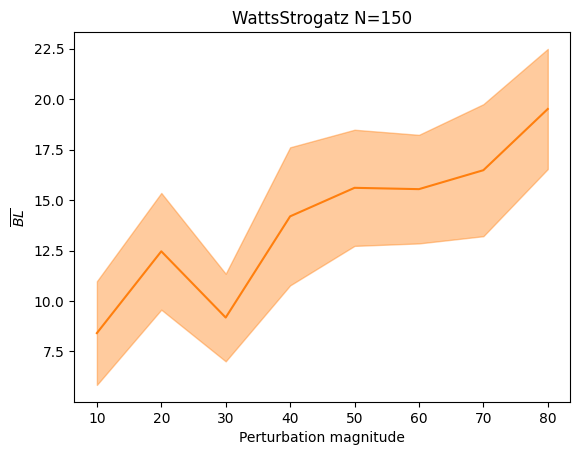

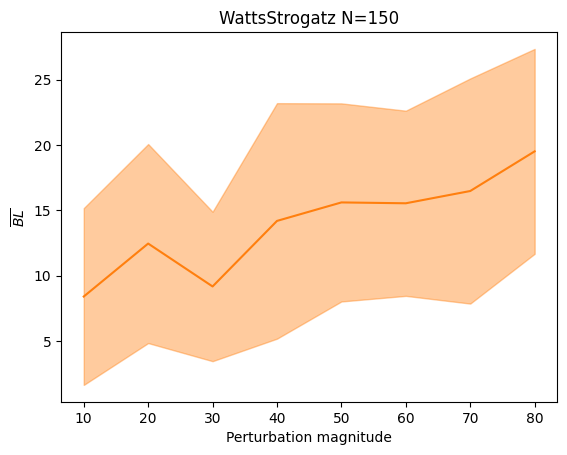

In [19]:
#BL_avg = np.average(score_global_avg_arr,axis=0)
BL_avg = np.array([mean_confidence_interval(score_global_avg_arr[:,i])[0] for i in range(len(mag_arr))])
BL_ = np.array([mean_confidence_interval(score_global_avg_arr[:,i])[1] for i in range(len(mag_arr))])
BL__ = np.array([mean_confidence_interval(score_global_avg_arr[:,i])[2] for i in range(len(mag_arr))])
x = mag_arr*100

plt.figure()
plt.plot(x,BL_avg, color='tab:orange')
plt.fill_between(x, BL_, BL__, alpha=0.4, color='tab:orange')
plt.xlabel('Perturbation magnitude')
plt.ylabel(r'$\overline{BL}$')
plt.title('%s N=150'%model)
plt.show()

BL_avg = np.average(score_global_avg_arr,axis=0)
BL_avg = np.array([mean_confidence_interval(score_global_avg_arr[:,i])[0] for i in range(len(mag_arr))])
BL_ = BL_avg - np.std(score_global_avg_arr,axis=0)
BL__ = BL_avg + np.std(score_global_avg_arr,axis=0)
x = mag_arr*100

plt.figure()
plt.plot(x,BL_avg, color='tab:orange')
plt.fill_between(x, BL_, BL__, alpha=0.4, color='tab:orange')
plt.xlabel('Perturbation magnitude')
plt.ylabel(r'$\overline{BL}$')
plt.title('%s N=150'%model)
plt.show()
